# Классификация банковских рисков по новостям

В работе исследуется автоматическое выявление банковских рисков в русскоязычных новостях. Основная задача — бинарная классификация: определить, содержит ли новость сообщение о риске. Дополнительно рассматривается классификация четырёх категорий: `no_risk`, `cyber_risk`, `operational_risk`, `regulatory_risk`.

Сравниваются Logistic Regression, LinearSVC и mDeBERTa. Модели обучались в Kaggle на исходном датасете с фиксированным разделением train/validation/test. Подбор параметров и выбор моделей основаны на validation; test используется только для итоговой оценки. Веса и результаты сохраняются в `/kaggle/working/bank_risk_diploma/`.

## 1. Окружение и данные

In [4]:
import os, sys, subprocess
os.environ['USE_TF'] = '0'
os.environ['USE_FLAX'] = '0'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '--disable-pip-version-check',
    'transformers==4.57.3', 'accelerate>=1.0,<2', 'sentencepiece>=0.2',
    'safetensors>=0.4'
])

0

In [16]:
from pathlib import Path
import gc, inspect, json, random, re, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch._utils
import joblib
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score,
    average_precision_score, precision_recall_curve, confusion_matrix,
    ConfusionMatrixDisplay)
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
    DataCollatorWithPadding, Trainer, TrainingArguments,
    EarlyStoppingCallback, set_seed)

SEED = 42
MODEL_ID = 'microsoft/mdeberta-v3-base'
MODEL_REVISION = 'a0484667b22365f84929a935b5e50a51f71f159d'
LABELS = ['no_risk', 'cyber_risk', 'operational_risk', 'regulatory_risk']
RUN_SEED_CHECK = True
RUN_FINAL_TEST = True
OUTPUT = Path('/kaggle/working/bank_risk_diploma')
OUTPUT.mkdir(parents=True, exist_ok=True)
set_seed(SEED)
assert torch.cuda.is_available(), 'Для обучения mDeBERTa необходим GPU в настройках Kaggle.'
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__)

def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding='utf-8')

def save_table(path, frame):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(path, index=False)

GPU: Tesla T4
PyTorch: 2.11.0+cu128


In [6]:
sources = sorted(Path('/kaggle/input').rglob('bank_risk_dataset.csv'))
assert len(sources) == 1, f'Ожидался один bank_risk_dataset.csv в Add Input, найдено: {sources}'
df = pd.read_csv(sources[0])
required = {'sample_id', 'event_group_id', 'split', 'text_fragment',
            'title', 'entity_norm', 'alert_flag', 'risk_type_4cls'}
assert required.issubset(df.columns), required - set(df.columns)
assert df['sample_id'].is_unique
assert set(df['split']) == {'train', 'valid', 'test'}
assert set(df['alert_flag']) == {0, 1}
assert set(df['risk_type_4cls']) == set(LABELS)
assert (df['alert_flag'].eq(0) == df['risk_type_4cls'].eq('no_risk')).all()
for col in ('text_fragment', 'title', 'entity_norm'):
    df[col] = df[col].fillna('').astype(str)
assert df['text_fragment'].str.strip().ne('').all()
parts = {s: df[df['split'].eq(s)].reset_index(drop=True)
         for s in ('train', 'valid', 'test')}
assert [len(parts[s]) for s in ('train', 'valid', 'test')] == [3535, 755, 751]
for a, b in (('train', 'valid'), ('train', 'test'), ('valid', 'test')):
    assert not set(parts[a]['event_group_id']) & set(parts[b]['event_group_id'])
print('Датасет:', sources[0], '| записей:', len(df))
display(pd.crosstab(df['split'], df['risk_type_4cls'])
        .reindex(index=['train', 'valid', 'test'], columns=LABELS))

Датасет: /kaggle/input/datasets/victordoynikov/bank-risks/bank_risk_dataset.csv | записей: 5041


risk_type_4cls,no_risk,cyber_risk,operational_risk,regulatory_risk
split,,,,
train,3359,74,67,35
valid,715,20,13,7
test,713,17,17,4


## 2. Анализ данных

В выборке преобладают новости без риска. Поэтому для бинарной классификации используется F1 положительного класса, а для многоклассовой — Macro F1, которая учитывает качество по всем четырём классам.

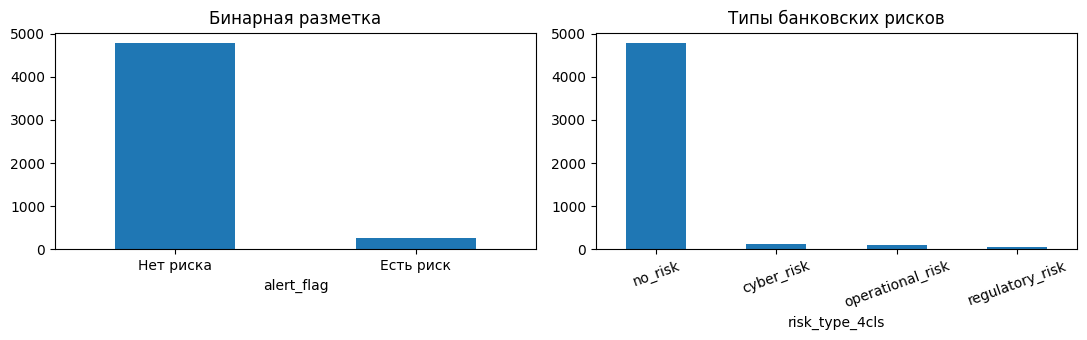

Доли risk/no-risk по выборкам:


alert_flag,0,1
split,,
test,0.9494,0.0506
train,0.9502,0.0498
valid,0.9470,0.0530


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df['alert_flag'].map({0:'Нет риска', 1:'Есть риск'}).value_counts().plot.bar(ax=ax[0], rot=0)
ax[0].set_title('Бинарная разметка')
df['risk_type_4cls'].value_counts().reindex(LABELS).plot.bar(ax=ax[1], rot=20)
ax[1].set_title('Типы банковских рисков')
plt.tight_layout()
plt.show()
print('Доли risk/no-risk по выборкам:')
display(pd.crosstab(df['split'], df['alert_flag'], normalize='index').round(4))

## 3. Бинарная классификация: классические модели

In [8]:
def binary_metrics(y, scores, threshold):
    y = np.asarray(y, dtype=int)
    scores = np.asarray(scores, dtype=float)
    pred = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'f1': float(f1_score(y, pred, zero_division=0)),
            'precision': float(precision_score(y, pred, zero_division=0)),
            'recall': float(recall_score(y, pred, zero_division=0)),
            'ap': float(average_precision_score(y, scores)),
            'threshold': float(threshold),
            'tp': int(tp), 'fp': int(fp), 'fn': int(fn), 'tn': int(tn)}

def choose_threshold(y, scores):
    p, r, t = precision_recall_curve(y, scores)
    f1 = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-12)
    return float(t[np.flatnonzero(np.isclose(f1, f1.max(), rtol=0, atol=1e-12))[-1]])

def positive_scores(estimator, texts):
    if hasattr(estimator, 'decision_function'):
        return np.asarray(estimator.decision_function(texts))
    return np.asarray(estimator.predict_proba(texts))[:, 1]

def classic_text(frame, with_bank):
    text = frame['text_fragment'].tolist()
    if with_bank:
        return ['Банк: ' + b + '. Новость: ' + t
                for b, t in zip(frame['entity_norm'], text)]
    return text

binary_results, binary_models = [], {}
y_train = parts['train']['alert_flag'].to_numpy()
y_valid = parts['valid']['alert_flag'].to_numpy()
for name in ('LogisticRegression', 'LinearSVC'):
    best = None
    for with_bank in (False, True):
        for ngrams in ((1, 1), (1, 2)):
            for weight in (None, 'balanced'):
                for c in (0.1, 1.0, 3.0):
                    if name == 'LogisticRegression':
                        clf = LogisticRegression(C=c, class_weight=weight,
                                                 random_state=SEED, max_iter=2000)
                    else:
                        clf = LinearSVC(C=c, class_weight=weight, random_state=SEED)
                    pipe = Pipeline([
                        ('tfidf', TfidfVectorizer(ngram_range=ngrams, min_df=2,
                                                 max_df=0.99, max_features=70000,
                                                 sublinear_tf=True)),
                        ('classifier', clf)])
                    pipe.fit(classic_text(parts['train'], with_bank), y_train)
                    scores = positive_scores(pipe, classic_text(parts['valid'], with_bank))
                    threshold = choose_threshold(y_valid, scores)
                    m = binary_metrics(y_valid, scores, threshold)
                    key = (m['f1'], m['ap'])
                    if best is None or key > best[0]:
                        best = (key, pipe, with_bank, m,
                                {'ngrams': ngrams, 'weight': weight, 'C': c})
    _, pipe, with_bank, metrics, params = best
    binary_models[name] = {'pipeline': pipe, 'with_bank': with_bank,
                           'threshold': metrics['threshold']}
    binary_results.append({'model': name, **metrics})
    joblib.dump(binary_models[name], OUTPUT / f'{name}_binary.joblib')
    print(name, params, 'Validation F1:', round(metrics['f1'], 4))
binary_valid = pd.DataFrame(binary_results)
save_table(OUTPUT / 'binary_validation.csv', binary_valid)
display(binary_valid[['model', 'f1', 'precision', 'recall', 'ap', 'fp', 'fn']].round(4))

LogisticRegression {'ngrams': (1, 1), 'weight': 'balanced', 'C': 3.0} Validation F1: 0.7273
LinearSVC {'ngrams': (1, 1), 'weight': 'balanced', 'C': 0.1} Validation F1: 0.7532


,model,f1,precision,recall,ap,fp,fn
0,LogisticRegression,0.7273,0.7568,0.700,0.7606,9,12
1,LinearSVC,0.7532,0.7838,0.725,0.7561,8,11


## 4. Бинарная классификация: mDeBERTa

Для нейросетевой модели используется банковский контекст: на вход подаются название банка и связанные с ним фрагменты новости. Дообучение проводится в течение не более шести эпох с выбором лучшего checkpoint по F1 на validation. Тестовая выборка на этапе настройки не используется.

In [9]:
def add_title(title, text):
    title, text = title.strip(), text.strip()
    if not title or title.lower() in text[:max(300, len(title) + 40)].lower():
        return text
    return title + '. ' + text

def bank_context(bank, text, title):
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    words = [x for x in re.findall(r'\w+', bank.casefold()) if len(x) >= 4]
    matches = [i for i, s in enumerate(sentences)
               if bank.casefold() in s.casefold()
               or any(word in s.casefold() for word in words)]
    if not matches:
        return add_title(title, text)
    indices = set()
    for i in matches:
        indices.update(range(max(0, i - 1), min(len(sentences), i + 2)))
    return add_title(title, ' '.join(sentences[i] for i in sorted(indices)))

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION, use_fast=False)
collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8)

class NewsDataset(torch.utils.data.Dataset):
    def __init__(self, frame, task, mode):
        if mode == 'bank_context':
            snippets = [bank_context(b, t, h) for b, t, h in zip(
                frame['entity_norm'], frame['text_fragment'], frame['title'])]
            encoded = tokenizer(frame['entity_norm'].tolist(), text_pair=snippets,
                                truncation='only_second', max_length=256)
        else:
            encoded = tokenizer(frame['text_fragment'].tolist(),
                                truncation=True, max_length=256)
        self.encoded = encoded
        if task == 'binary':
            self.labels = frame['alert_flag'].astype(int).tolist()
        else:
            label_to_id = {v: i for i, v in enumerate(LABELS)}
            self.labels = frame['risk_type_4cls'].map(label_to_id).astype(int).tolist()
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return {**{k: v[i] for k, v in self.encoded.items()}, 'labels': self.labels[i]}

def softmax_positive(logits):
    x = np.asarray(logits, dtype=np.float64)
    x = x - x.max(axis=-1, keepdims=True)
    z = np.exp(x)
    return (z / z.sum(axis=-1, keepdims=True))[:, 1]

def epoch_binary_metrics(pred):
    logits = pred.predictions[0] if isinstance(pred.predictions, tuple) else pred.predictions
    scores = softmax_positive(logits)
    t = choose_threshold(pred.label_ids, scores)
    return {k: v for k, v in binary_metrics(pred.label_ids, scores, t).items()
            if k != 'threshold'}

def epoch_multi_metrics(pred):
    logits = pred.predictions[0] if isinstance(pred.predictions, tuple) else pred.predictions
    guesses = np.asarray(logits).argmax(axis=1)
    return {'macro_f1': float(f1_score(pred.label_ids, guesses,
                                     labels=range(4), average='macro', zero_division=0))}

def trainer_args(folder, seed, metric):
    params = dict(output_dir=str(folder), num_train_epochs=6,
                  learning_rate=2e-5, weight_decay=0.01, warmup_ratio=0.1,
                  per_device_train_batch_size=4, per_device_eval_batch_size=8,
                  gradient_accumulation_steps=4, lr_scheduler_type='linear',
                  optim='adamw_torch', max_grad_norm=1.0,
                  eval_strategy='epoch', save_strategy='epoch',
                  logging_strategy='epoch', load_best_model_at_end=True,
                  metric_for_best_model=metric, greater_is_better=True,
                  save_total_limit=1, save_safetensors=True,
                  fp16=not torch.cuda.is_bf16_supported(),
                  bf16=torch.cuda.is_bf16_supported(),
                  seed=seed, data_seed=seed, report_to='none',
                  dataloader_num_workers=0)
    available = set(inspect.signature(TrainingArguments).parameters)
    if 'eval_strategy' not in available:
        params['evaluation_strategy'] = params.pop('eval_strategy')
    return TrainingArguments(**{k: v for k, v in params.items() if k in available})

def train_mdeberta(task, mode, seed=SEED, name=None):
    name = name or task
    folder = OUTPUT / name
    best_model_dir = folder / 'best_model'
    done = folder / 'validation.json'
    if done.exists() and (best_model_dir / 'config.json').exists():
        print('Используется уже обученная модель:', name)
        return json.loads(done.read_text(encoding='utf-8'))
    set_seed(seed)
    n_labels = 2 if task == 'binary' else 4
    names = ['no_risk', 'risk'] if task == 'binary' else LABELS
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_ID, revision=MODEL_REVISION, num_labels=n_labels,
        id2label=dict(enumerate(names)), label2id={s: i for i, s in enumerate(names)})
    model = model.float()
    train_ds = NewsDataset(parts['train'], task, mode)
    valid_ds = NewsDataset(parts['valid'], task, mode)
    args = trainer_args(folder / 'checkpoints', seed,
                        'f1' if task == 'binary' else 'macro_f1')
    kwargs = dict(model=model, args=args, train_dataset=train_ds,
                  eval_dataset=valid_ds, data_collator=collator,
                  compute_metrics=epoch_binary_metrics if task == 'binary' else epoch_multi_metrics,
                  callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
    trainer_signature = set(inspect.signature(Trainer).parameters)
    if 'processing_class' in trainer_signature:
        kwargs['processing_class'] = tokenizer
    elif 'tokenizer' in trainer_signature:
        kwargs['tokenizer'] = tokenizer
    trainer = Trainer(**kwargs)
    trainer.train()
    trainer.save_model(str(best_model_dir))
    tokenizer.save_pretrained(str(best_model_dir))
    prediction = trainer.predict(valid_ds)
    logits = prediction.predictions[0] if isinstance(prediction.predictions, tuple) else prediction.predictions
    if task == 'binary':
        scores = softmax_positive(logits)
        threshold = choose_threshold(prediction.label_ids, scores)
        metrics = binary_metrics(prediction.label_ids, scores, threshold)
        frame = parts['valid'][['sample_id', 'alert_flag']].copy()
        frame['score'] = scores
        frame['prediction'] = (scores >= threshold).astype(int)
    else:
        guesses = np.asarray(logits).argmax(axis=1)
        metrics = multi_metrics(prediction.label_ids, guesses)
        frame = parts['valid'][['sample_id', 'risk_type_4cls']].copy()
        frame['prediction'] = [LABELS[x] for x in guesses]
    save_table(folder / 'valid_predictions.csv', frame)
    save_table(folder / 'training_history.csv', pd.DataFrame(trainer.state.log_history))
    record = {'task': task, 'mode': mode, 'seed': seed, **metrics}
    save_json(done, record)
    shutil.rmtree(folder / 'checkpoints', ignore_errors=True)
    del trainer, prediction, model, train_ds, valid_ds
    gc.collect()
    torch.cuda.empty_cache()
    return record

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

In [10]:
binary_dl = train_mdeberta('binary', mode='bank_context', seed=SEED,
                            name='binary_mdeberta')
print('mDeBERTa — validation:')
display(pd.DataFrame([binary_dl])[['f1', 'precision', 'recall', 'ap', 'fp', 'fn']].round(4))

pytorch_model.bin:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/mdeberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


model.safetensors:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,F1,Precision,Recall,Ap,Tp,Fp,Fn,Tn
1,0.251800,0.197053,0.609756,0.595238,0.625000,0.465879,25,17,15,698
2,0.112600,0.107566,0.696629,0.632653,0.775000,0.688165,31,18,9,697
3,0.065900,0.094180,0.759494,0.769231,0.750000,0.798549,30,9,10,706
4,0.049900,0.117284,0.736842,0.777778,0.700000,0.774881,28,8,12,707
5,0.033000,0.108130,0.767123,0.848485,0.700000,0.817756,28,5,12,710
6,0.024200,0.111823,0.767123,0.848485,0.700000,0.812971,28,5,12,710


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

mDeBERTa — validation:


,f1,precision,recall,ap,fp,fn
0,0.7671,0.8485,0.7,0.8178,5,12


## 5. Дополнительная задача: четыре класса риска

Многоклассовая постановка позволяет отличать киберриски, операционные и регуляторные риски от нейтральных новостей. Для оценки используется Macro F1.

In [11]:
def multi_metrics(y, pred):
    y, pred = np.asarray(y, dtype=int), np.asarray(pred, dtype=int)
    scores = f1_score(y, pred, labels=range(4), average=None, zero_division=0)
    result = {'macro_f1': float(scores.mean()),
              'risk_macro_f1': float(scores[1:].mean()),
              'macro_precision': float(precision_score(y, pred, labels=range(4),
                                          average='macro', zero_division=0)),
              'macro_recall': float(recall_score(y, pred, labels=range(4),
                                       average='macro', zero_division=0))}
    result.update({f'f1_{name}': float(scores[i]) for i, name in enumerate(LABELS)})
    return result

def multi_text(frame, mode):
    if mode == 'text':
        return frame['text_fragment'].tolist()
    excerpts = [bank_context(b, t, h) for b, t, h in zip(
        frame['entity_norm'], frame['text_fragment'], frame['title'])]
    return ['Банк: ' + b + '. ' + x for b, x in zip(frame['entity_norm'], excerpts)]

def multi_features():
    return FeatureUnion([
        ('word', TfidfVectorizer(analyzer='word', ngram_range=(1, 2),
                                 min_df=2, max_features=45000, sublinear_tf=True,
                                 dtype=np.float32)),
        ('char', TfidfVectorizer(analyzer='char', ngram_range=(3, 4),
                                 min_df=3, max_features=45000, sublinear_tf=True,
                                 dtype=np.float32))])

multi_records, multi_models = [], {}
lab_to_id = {name: i for i, name in enumerate(LABELS)}
y_multi_train = parts['train']['risk_type_4cls'].map(lab_to_id).to_numpy()
y_multi_valid = parts['valid']['risk_type_4cls'].map(lab_to_id).to_numpy()
for name in ('LogisticRegression', 'LinearSVC'):
    for mode in ('text', 'bank_context'):
        clf = (OneVsRestClassifier(LogisticRegression(
            C=1.0, class_weight='balanced', random_state=SEED,
            solver='liblinear', max_iter=500)) if name == 'LogisticRegression'
            else LinearSVC(C=1.0, class_weight='balanced', random_state=SEED,
                           max_iter=4000))
        pipe = Pipeline([('tfidf', multi_features()), ('classifier', clf)])
        pipe.fit(multi_text(parts['train'], mode), y_multi_train)
        pred = pipe.predict(multi_text(parts['valid'], mode))
        record = {'model': name + '_' + mode, **multi_metrics(y_multi_valid, pred)}
        multi_records.append(record)
        multi_models[record['model']] = (pipe, mode)
        joblib.dump({'pipeline': pipe, 'mode': mode},
                    OUTPUT / (record['model'] + '_multiclass.joblib'))
multi_valid = pd.DataFrame(multi_records).sort_values('macro_f1', ascending=False)
save_table(OUTPUT / 'multiclass_validation.csv', multi_valid)
display(multi_valid[['model', 'macro_f1', 'risk_macro_f1']].round(4))

,model,macro_f1,risk_macro_f1
0,LogisticRegression_text,0.7446,0.6642
1,LogisticRegression_bank_context,0.7381,0.6557
2,LinearSVC_text,0.6159,0.4930
3,LinearSVC_bank_context,0.6048,0.4786


In [12]:
multi_dl = train_mdeberta('multiclass', mode='text', seed=SEED,
                           name='multiclass_mdeberta')
print('mDeBERTa — validation:')
display(pd.DataFrame([multi_dl])[['macro_f1', 'risk_macro_f1']].round(4))

Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/mdeberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Macro F1
1,0.557000,0.168194,0.243197
2,0.167300,0.190339,0.442068
3,0.099300,0.128038,0.563397
4,0.065400,0.123022,0.634033
5,0.038400,0.122679,0.751226
6,0.027300,0.117381,0.746892


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

mDeBERTa — validation:


,macro_f1,risk_macro_f1
0,0.7512,0.6727


## 6. Проверка устойчивости нейросети

Для обеих задач выполнены три запуска mDeBERTa с random seed 42, 123 и 2026. Все запуски используют одинаковые данные и параметры обучения. Качество сравнивается только на validation. Основной моделью для финального test остаётся исходная модель с seed 42.

In [17]:
seed_records = [{'seed': SEED, 'macro_f1': multi_dl['macro_f1']}]
if RUN_SEED_CHECK:
    for seed in (123, 2026):
        record = train_mdeberta('multiclass', 'text', seed=seed,
                                name=f'multiclass_seed_{seed}')
        seed_records.append({'seed': seed, 'macro_f1': record['macro_f1']})
seed_table = pd.DataFrame(seed_records)
save_table(OUTPUT / 'seed_stability.csv', seed_table)
display(seed_table.round(4))

Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/mdeberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Macro F1
1,0.544600,0.181308,0.243197
2,0.212400,0.177198,0.336755
3,0.136600,0.155007,0.432159
4,0.115800,0.176977,0.485963
5,0.080500,0.184186,0.523805
6,0.064800,0.158302,0.553707


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/mdeberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Macro F1
1,0.555300,0.233446,0.243197
2,0.149200,0.155718,0.355098
3,0.100000,0.231730,0.450148
4,0.065100,0.191592,0.522795
5,0.040800,0.130231,0.724547
6,0.028800,0.125608,0.737221


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

,seed,macro_f1
0,42,0.7512
1,123,0.5537
2,2026,0.7372


In [20]:
binary_seed_records = [{
    'seed': 42,
    'f1': binary_dl['f1']
}]

for seed in (123, 2026):
    record = train_mdeberta(
        'binary',
        mode='bank_context',
        seed=seed,
        name=f'binary_seed_{seed}'
    )
    binary_seed_records.append({
        'seed': seed,
        'f1': record['f1']
    })

binary_seed_table = pd.DataFrame(binary_seed_records)
save_table(OUTPUT / 'binary_seed_stability.csv', binary_seed_table)
display(binary_seed_table.round(4))

Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/mdeberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,F1,Precision,Recall,Ap,Tp,Fp,Fn,Tn
1,0.278800,0.107452,0.651163,0.608696,0.700000,0.581515,28,18,12,697
2,0.097800,0.111091,0.682353,0.644444,0.725000,0.692224,29,16,11,699
3,0.066200,0.111011,0.746988,0.720930,0.775000,0.758628,31,12,9,703
4,0.042300,0.112355,0.755556,0.680000,0.850000,0.732075,34,16,6,699
5,0.024700,0.130398,0.755556,0.680000,0.850000,0.826907,34,16,6,699
6,0.017100,0.131644,0.741573,0.673469,0.825000,0.834971,33,16,7,699


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/mdeberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,F1,Precision,Recall,Ap,Tp,Fp,Fn,Tn
1,0.304800,0.177013,0.688889,0.620000,0.775000,0.604165,31,19,9,696
2,0.102800,0.170157,0.712644,0.659574,0.775000,0.622333,31,16,9,699
3,0.060600,0.144136,0.716049,0.707317,0.725000,0.722810,29,12,11,703
4,0.042000,0.107109,0.777778,0.875000,0.700000,0.800396,28,4,12,711
5,0.028900,0.122719,0.736842,0.777778,0.700000,0.782240,28,8,12,707
6,0.021500,0.116351,0.767123,0.848485,0.700000,0.798709,28,5,12,710


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

,seed,f1
0,42,0.7671
1,123,0.7556
2,2026,0.7778


### Результаты проверки устойчивости

| Seed | Бинарная классификация, Validation F1 | Четыре класса, Validation Macro F1 |
|---|---:|---:|
| 42 | 0,7671 | 0,7512 |
| 123 | 0,7556 | 0,5537 |
| 2026 | 0,7778 | 0,7372 |

В бинарной задаче результаты трёх запусков близки. В многоклассовой задаче разброс заметно больше, особенно для seed 123. Следовательно, качество многоклассовой mDeBERTa существенно зависит от случайной инициализации. Эти повторные запуски не использовались для выбора модели по результатам test.

## 7. Итоговая оценка на test

Параметры всех моделей и порог бинарного классификатора определены по validation. На test выполняется только итоговая оценка, без подбора моделей или гиперпараметров. Сохранённые результаты не используются для повторной настройки.

In [18]:
def pretrained_predictions(name, task, mode):
    model_dir = OUTPUT / name / 'best_model'
    assert (model_dir / 'config.json').is_file(), model_dir
    model = AutoModelForSequenceClassification.from_pretrained(str(model_dir))
    ds = NewsDataset(parts['test'], task, mode)
    predict_args = TrainingArguments(
        output_dir=str(OUTPUT / '_predict_tmp'), per_device_eval_batch_size=8,
        report_to='none', save_strategy='no', eval_strategy='no',
        fp16=not torch.cuda.is_bf16_supported(),
        bf16=torch.cuda.is_bf16_supported())
    kwargs = dict(model=model, args=predict_args, data_collator=collator)
    sig = set(inspect.signature(Trainer).parameters)
    if 'processing_class' in sig:
        kwargs['processing_class'] = tokenizer
    elif 'tokenizer' in sig:
        kwargs['tokenizer'] = tokenizer
    predictor = Trainer(**kwargs)
    result = predictor.predict(ds)
    logits = result.predictions[0] if isinstance(result.predictions, tuple) else result.predictions
    del predictor, model, ds, result
    gc.collect()
    torch.cuda.empty_cache()
    return logits

if RUN_FINAL_TEST:
    binary_test_rows = []
    for name, record in binary_models.items():
        scores = positive_scores(record['pipeline'],
                                 classic_text(parts['test'], record['with_bank']))
        m = binary_metrics(parts['test']['alert_flag'], scores, record['threshold'])
        binary_test_rows.append({'model': name, **m})
    logits = pretrained_predictions('binary_mdeberta', 'binary', 'bank_context')
    dl_scores = softmax_positive(logits)
    binary_test_rows.append({'model': 'mDeBERTa', **binary_metrics(
        parts['test']['alert_flag'], dl_scores, binary_dl['threshold'])})
    binary_test = pd.DataFrame(binary_test_rows)
    save_table(OUTPUT / 'binary_test.csv', binary_test)

    multi_test_rows = []
    for name, (pipe, mode) in multi_models.items():
        guesses = pipe.predict(multi_text(parts['test'], mode))
        multi_test_rows.append({'model': name, **multi_metrics(
            parts['test']['risk_type_4cls'].map(lab_to_id), guesses)})
    multi_logits = pretrained_predictions('multiclass_mdeberta', 'multiclass', 'text')
    dl_multi_pred = np.asarray(multi_logits).argmax(axis=1)
    multi_test_rows.append({'model': 'mDeBERTa', **multi_metrics(
        parts['test']['risk_type_4cls'].map(lab_to_id), dl_multi_pred)})
    multi_test = pd.DataFrame(multi_test_rows)
    save_table(OUTPUT / 'multiclass_test.csv', multi_test)
    save_table(OUTPUT / 'dl_multiclass_test_predictions.csv', pd.DataFrame({
        'sample_id': parts['test']['sample_id'],
        'label': parts['test']['risk_type_4cls'],
        'prediction': [LABELS[x] for x in dl_multi_pred]}))
    print('Бинарная классификация, test:')
    display(binary_test[['model', 'f1', 'precision', 'recall', 'fp', 'fn']].round(4))
    print('Многоклассовая классификация, test:')
    display(multi_test[['model', 'macro_f1', 'risk_macro_f1']].round(4))
else:
    print('Финальное тестирование отключено.')

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Бинарная классификация, test:


,model,f1,precision,recall,fp,fn
0,LogisticRegression,0.8861,0.8537,0.9211,6,3
1,LinearSVC,0.8642,0.8140,0.9211,8,3
2,mDeBERTa,0.8378,0.8611,0.8158,5,7


Многоклассовая классификация, test:


,model,macro_f1,risk_macro_f1
0,LogisticRegression_text,0.8206,0.7639
1,LogisticRegression_bank_context,0.8241,0.7683
2,LinearSVC_text,0.7834,0.7137
3,LinearSVC_bank_context,0.7719,0.6987
4,mDeBERTa,0.8417,0.7917


## 8. Сравнение и выводы

Основная модель в каждой задаче определялась по **validation**. Для бинарной классификации mDeBERTa (F1 = 0,7671) опередила лучшую классическую модель LinearSVC (0,7532). Для многоклассовой классификации mDeBERTa (Macro F1 = 0,7512) опередила Logistic Regression на текстовых признаках (0,7446).

Следующая ячейка показывает **максимальные показатели на test только для описательного сравнения**. Эти показатели не используются для повторного выбора модели или настройки гиперпараметров.

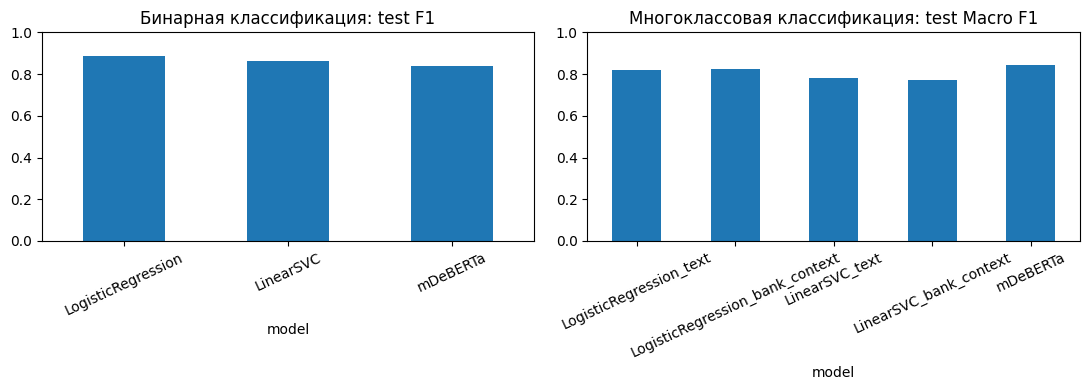

Наибольший test F1 (бинарная): LogisticRegression, 0.8861
Наибольший test Precision (бинарная): mDeBERTa, 0.8611
Наибольший test Macro F1 (четыре класса): mDeBERTa, 0.8417


In [19]:
if RUN_FINAL_TEST:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    binary_test.set_index('model')['f1'].plot.bar(ax=axes[0], rot=25)
    axes[0].set_title('Бинарная классификация: test F1')
    axes[0].set_ylim(0, 1)
    multi_test.set_index('model')['macro_f1'].plot.bar(ax=axes[1], rot=25)
    axes[1].set_title('Многоклассовая классификация: test Macro F1')
    axes[1].set_ylim(0, 1)
    plt.tight_layout()
    plt.savefig(OUTPUT / 'final_comparison.png', dpi=150)
    plt.show()
    best_bin_f1 = binary_test.sort_values('f1', ascending=False).iloc[0]
    best_bin_precision = binary_test.sort_values('precision', ascending=False).iloc[0]
    best_multi = multi_test.sort_values('macro_f1', ascending=False).iloc[0]
    print(f'Наибольший test F1 (бинарная): {best_bin_f1.model}, {best_bin_f1.f1:.4f}')
    print(f'Наибольший test Precision (бинарная): {best_bin_precision.model}, '
          f'{best_bin_precision.precision:.4f}')
    print(f'Наибольший test Macro F1 (четыре класса): {best_multi.model}, '
          f'{best_multi.macro_f1:.4f}')
    save_json(OUTPUT / 'summary.json', {
        'binary_test': binary_test.to_dict(orient='records'),
        'multiclass_test': multi_test.to_dict(orient='records'),
        'train_size': len(parts['train']), 'valid_size': len(parts['valid']),
        'test_size': len(parts['test']), 'seed_check': bool(RUN_SEED_CHECK)})

### Общий вывод

В основной, бинарной задаче mDeBERTa показала наибольший F1 на validation (0,7671), причём результаты трёх запусков с разными seed оказались близкими. На test более высокий F1 получила Logistic Regression — 0,8861 против 0,8378 у mDeBERTa. Нейросеть немного превосходит её по Precision (0,8611 против 0,8537) и допускает на одно ложное предупреждение меньше (5 против 6), но чаще пропускает риск (7 против 3). Поэтому выбор между моделями зависит от того, что важнее для практической системы: уменьшить ложные тревоги или не пропускать рисковые события.

В дополнительной задаче определения типа риска mDeBERTa достигла Test Macro F1 = 0,8417, а лучшая по validation классическая модель Logistic Regression — 0,8206. Однако проверка seed выявила заметную нестабильность многоклассовой нейросети: Validation Macro F1 изменялся от 0,5537 до 0,7512. Полученное преимущество на test следует интерпретировать с учётом небольшого числа примеров редких классов.

В целом глубокое обучение оказалось конкурентоспособным, но не превосходило классические модели по всем критериям. Результаты показывают, что при выборе модели необходимо учитывать не только итоговую метрику, но и баланс ложных срабатываний и пропусков, устойчивость обучения и затраты на вычисления.